# Batch effects in clonal embeddings

**Why can a batch effect reach the clonal embedding at all?** clone2vec describes each clone by which clones its cells neighbour in expression space. Suppose the cells of one patient sit slightly apart from everyone else in that space, because of a batch effect that wasn't fully removed. Then they mostly neighbour each other, and that patient's clones share neighbourhoods with each other more than with anyone else. The embedding faithfully reports this, and the patient's clones end up grouped together.

The best fix is upstream: integrate the cells well before building the embedding. But when some batch effect slips through, it can also be corrected **in the clonal space itself**. All clones live in one shared clone2vec space, so the same tools that integrate cells (bbknn, Harmony) can integrate clones.

**The plan:**

1. Load the CD8 T cell clonal embedding of the Liu et al. NSCLC cohort, built in [Graph input for clonal embeddings construction](Graph_input.ipynb).
2. Diagnose: do clones group by patient?
3. Correct the clonal kNN graph with bbknn.
4. Check that the clonal clusters and their marker genes don't change.

## Setup

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import clone2vec as c2v
import scanpy.external as sce

sc.set_figure_params(dpi=80)
sc.settings.verbosity = 3
sns.set_style("ticks")

## Step 1: Load the clonal object

`Liu_CD8_bbknn_c2v.h5ad` was saved at the end of the graph input notebook. It contains the clone2vec embedding, the clonal clusters (`leiden`), the patient of each clone (`gex_patient`), and the average expression of each clone.

In [2]:
clones = sc.read_h5ad("Liu_CD8_bbknn_c2v.h5ad")

## Step 2: Diagnose

The simplest check is to colour the clonal UMAP by batch, here the patient. T cell receptor clones are patient-specific, so every clone belongs to exactly one patient. In a batch-free embedding, the patients should be mixed throughout the map.

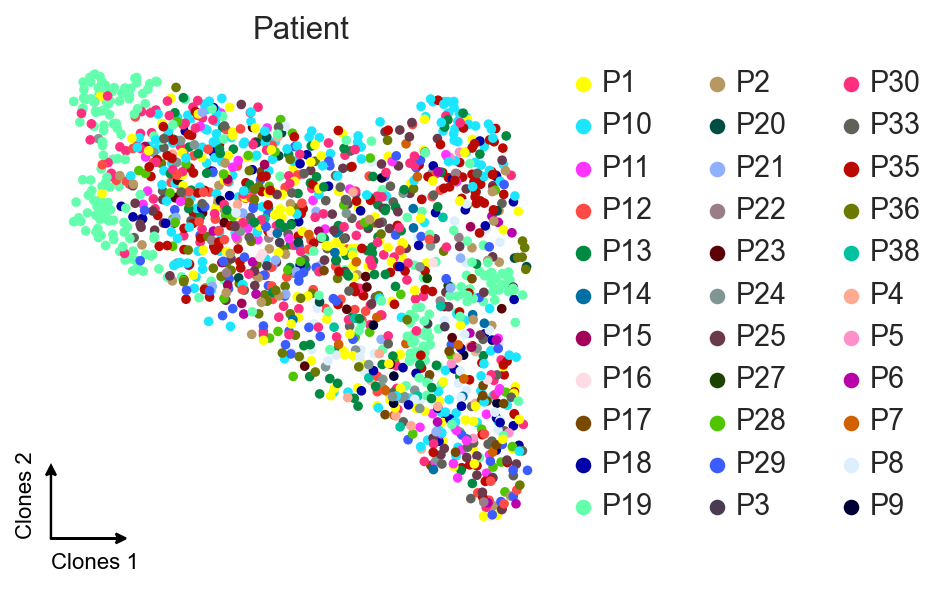

In [4]:
ax = sc.pl.umap(clones, color="gex_patient", title="Patient",
                frameon=False, show=False)
c2v.pl.embedding_axis(ax, label="Clones")

**What to look for:** most patients are well mixed, but the clones of patient P19 (light green) concentrate at the left edge and in patches on the right. That's the signature of a batch effect that propagated from the expression space into the clonal space.

## Step 3: Correct the clonal kNN graph with bbknn

bbknn (batch-balanced kNN) builds the kNN graph so that every clone takes its nearest neighbours **from each batch separately**: here `neighbors_within_batch=2` neighbours from each patient. A P19 clone can then no longer connect only to other P19 clones. It is forced to link to the most similar clones of other patients. `trim=20` keeps only the strongest connections to avoid spurious links.

Note that bbknn changes only the **graph**, not the clone2vec vectors themselves. The new UMAP and anything computed from the graph will be batch-corrected, while `clones.obsm["clone2vec"]` stays as it was.

In [5]:
sce.pp.bbknn(clones, use_rep="clone2vec", batch_key="gex_patient",
             neighbors_within_batch=2, trim=20)

computing batch balanced neighbors
	finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:04)


In [6]:
sc.tl.umap(clones)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:03)


## Step 4: Did the correction change the biology?

On the new, corrected UMAP we plot two things: the patients, to see whether they are now mixed, and the clonal clusters computed **before** the correction, from the original embedding.

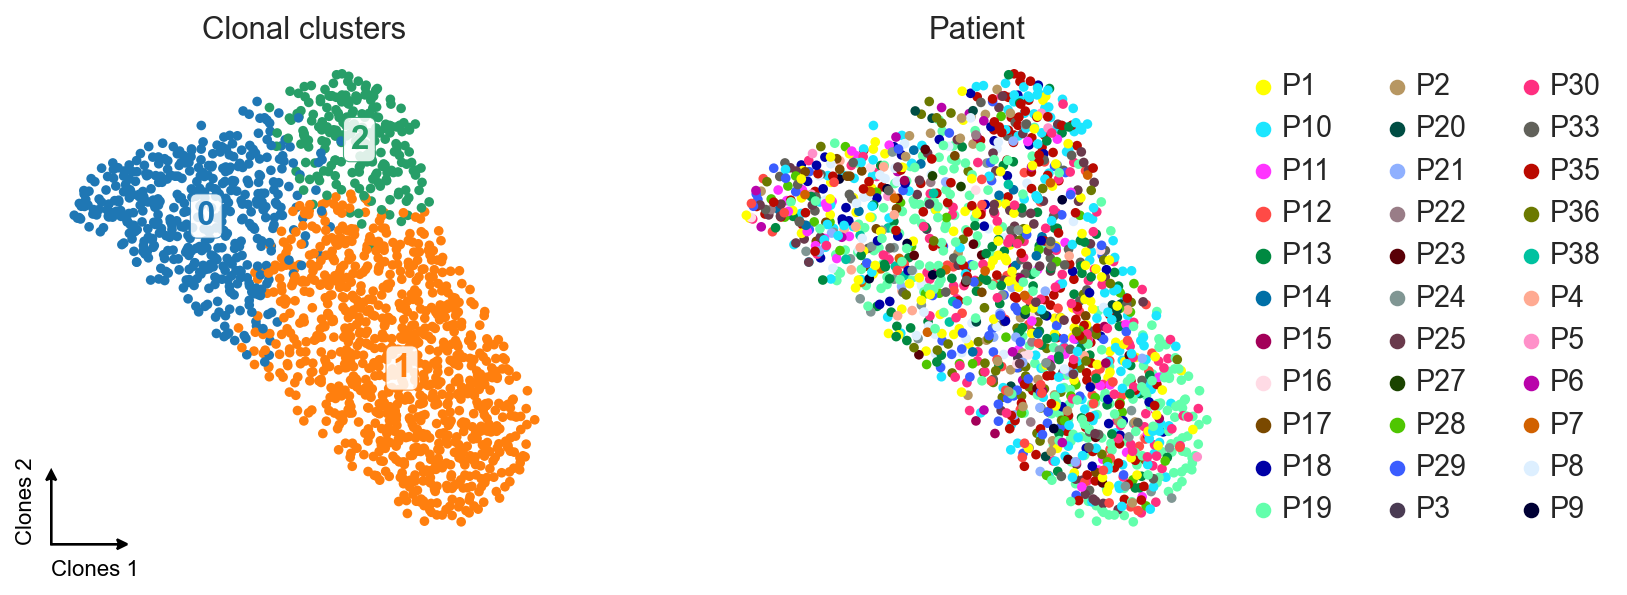

In [7]:
axes = sc.pl.umap(
    clones,
    color=["leiden", "gex_patient"],
    title=["Clonal clusters", "Patient"],
    frameon=False,
    show=False,
)

c2v.pl.embedding_axis(axes[0], label="Clones")
c2v.pl.fancy_legend(axes[0], fontweight="bold", center_loc=True, textsize=15)

**What to look for:**

* **Patients (right):** P19 clones are now spread through the map like everyone else's.
* **Clusters (left):** the original clusters 0, 1 and 2 still occupy compact, separate regions on the corrected map.

The batch effect moved P19 clones around but did not create or split the clonal clusters, so it was safe to work with the original embedding. If a cluster had been made mostly of one patient's clones, it would have dissolved here.

As a final check, the markers of the three clusters should keep the same pattern on the corrected map.

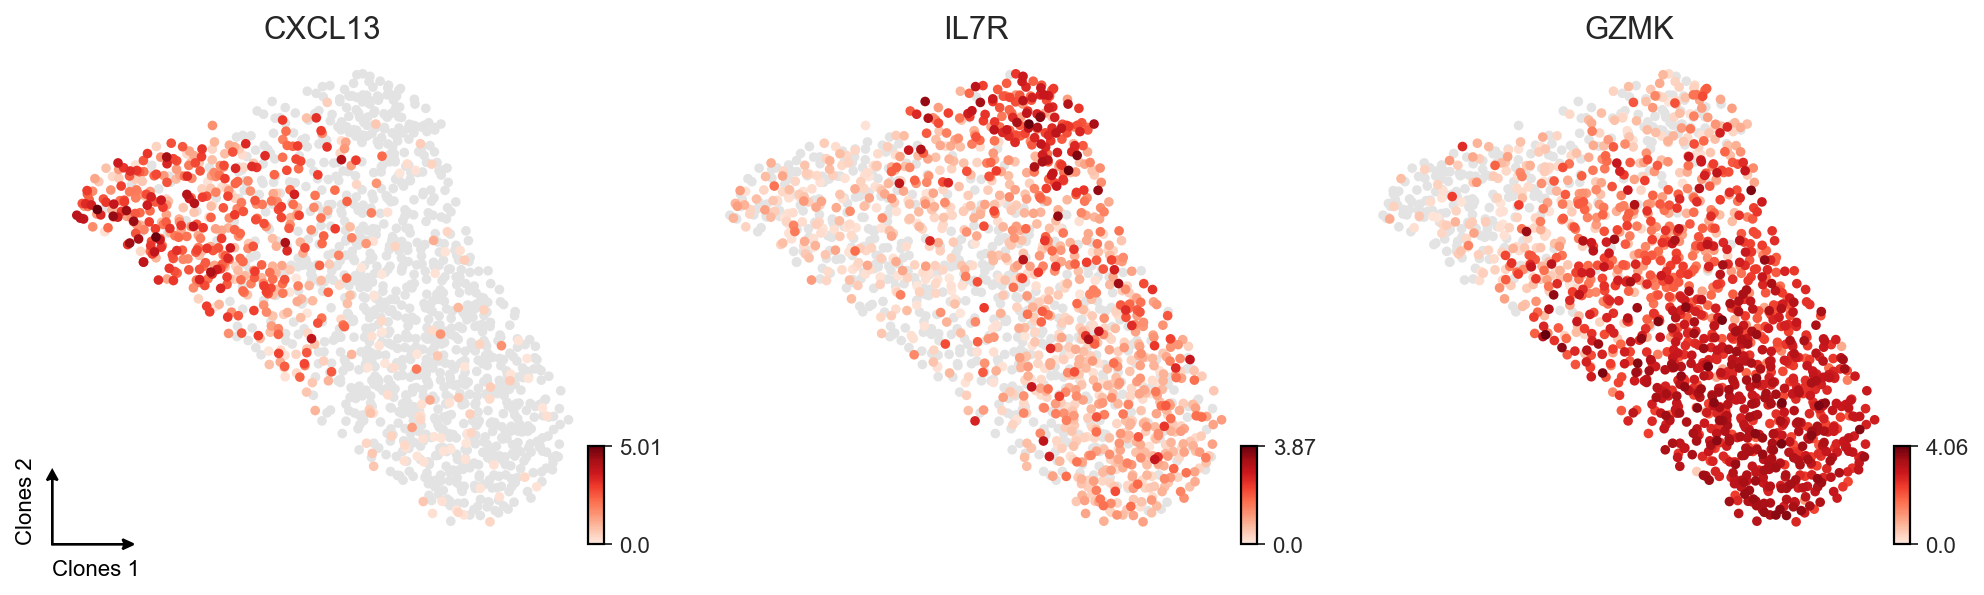

In [8]:
axes = sc.pl.umap(clones, color=["CXCL13", "IL7R", "GZMK"], frameon=False,
                  show=False, cmap=c2v.pl.Reds)

c2v.pl.small_cbar(axes)
c2v.pl.embedding_axis(axes[0], label="Clones")

**What to look for:** CXCL13 (exhausted, tumour-reactive clones), GZMK and IL7R still mark three distinct regions, the same programs as before the correction.

## Takeaways

* A batch effect in the expression space can propagate into the clonal embedding. **Always colour the clonal map by batch.**
* If it does, correct it upstream (better cell integration) or downstream on the clonal space, with bbknn or Harmony on `clone2vec`.
* Then check that your conclusions (clusters, markers) don't depend on the correction.
* bbknn and Harmony are non-linear corrections. Use them for visualization and clustering. The linear properties of the clonal space (e.g. mixed clones sitting between pure ones) hold only in the uncorrected `clone2vec` embedding or after a linear alignment (see [Integration of clonal embeddings](Integration.ipynb)).